#Day 40 End to End Mini Proect Classification

Ini adalah **proyek penutup modul klasifikasi**. Saya akan merangkai semua yang sudah dipelajari menjadi satu alur profesional: dari data mentah → **Pipeline** (encoding + scaling) → **GridSearchCV** (tuning) → evaluasi → **insight bisnis**.

Kasus: memprediksi pelanggan telekomunikasi yang akan **berhenti berlangganan (churn)**.

> 🎯 **Tujuan Pembelajaran**
> - Membangun alur ML rapi dengan `Pipeline` + `ColumnTransformer` (mencegah kebocoran data).
> - Melakukan **encoding** kategori & **scaling** numerik secara otomatis dalam satu objek.
> - Menyetel hyperparameter dengan **GridSearchCV** kecil.
> - Mengevaluasi model & menerjemahkan hasil menjadi **rekomendasi bisnis**.

## About Dataset

Dataset **Telco Customer Churn** berisi data pelanggan sebuah perusahaan telekomunikasi:

layanan yang dipakai, info kontrak, tagihan, dan status churn.

- **Sumber:** [Kaggle — blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Jumlah data:** 7.043 baris × 21 kolom

| Kolom | Arti |
|-------|------|
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Demografi |
| `tenure` | Lama berlangganan (bulan) |
| `Contract`, `PaymentMethod`, `PaperlessBilling` | Info kontrak & pembayaran |
| `MonthlyCharges`, `TotalCharges` | Tagihan |
| `InternetService`, `OnlineSecurity`, dll. | Layanan yang dipakai |
| `Churn` | **Target**: Yes = berhenti, No = bertahan |

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → visualisasi.
- **sklearn** → `Pipeline`, `ColumnTransformer`, `OneHotEncoder`, `StandardScaler`,  `LogisticRegression`, `GridSearchCV`, dan metrik evaluasi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score, RocCurveDisplay

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d blastchar/telco-customer-churn
!unzip telco-customer-churn.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
License(s): copyright-authors
100% 172k/172k [00:00<00:00, 67.5MB/s]

Archive:  telco-customer-churn.zip
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


## Early Exploration Data

In [4]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isna().sum().sum()

np.int64(0)

In [15]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Jumlah duplikat: {df.duplicated().sum()}')
print(f'Jumlah missing value: {df.isna().sum().sum()}')
print(f"Proporsi Target: {(df['Churn']=='Yes').mean():.2%}")

Jumlah baris: 7043
Jumlah kolom: 21
Jumlah duplikat: 0
Jumlah missing value: 0
Proporsi Target: 26.54%


**Interpretasi:**
- **Ukuran Data**: Dataset terdiri dari **7.043 baris** dan **21 kolom**.
- **Kualitas Data**: Tidak ditemukan duplikasi data (`0` duplikat) dan secara default tidak ada *missing value* (`0`). Namun, tipe data `TotalCharges` adalah `object`, yang mengindikasikan adanya nilai kosong berupa string spasi (`" "`) yang perlu dibersihkan.
- **Proporsi Target**: Tingkat churn (*positive class*) berada di angka **26.54%**. Kondisi data ini cukup *imbalanced* (tidak seimbang), sehingga metrik seperti *Recall*, *F1-Score*, atau *ROC-AUC* akan lebih relevan dibandingkan sekadar *Accuracy*.

## Cleaning Dataset

- Kolom `TotalCharges` sebenarnya angka, tapi terbaca sebagai teks karena ada nilai kosong
(spasi) pada pelanggan baru (`tenure`=0).
- Kita ubah ke numerik dan isi nilai kosong dengan 0.
- Kolom `customerID` kita buang karena hanya pengenal unik (tidak prediktif).

In [16]:
#Ubah nilai kosong menjadi 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [17]:
#hapus kolom customerID
df.drop(columns=["customerID"], inplace=True)

In [18]:
#Ubah target object menjadi numerik 1 & 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


**Interpretasi:**
- Kolom `TotalCharges` dan `Churn` sudah berubah menjadi kolom numerik

## Exploratory Data Analysis and Visualization

### a) Churn Berdasarkan Jenis Kontrak

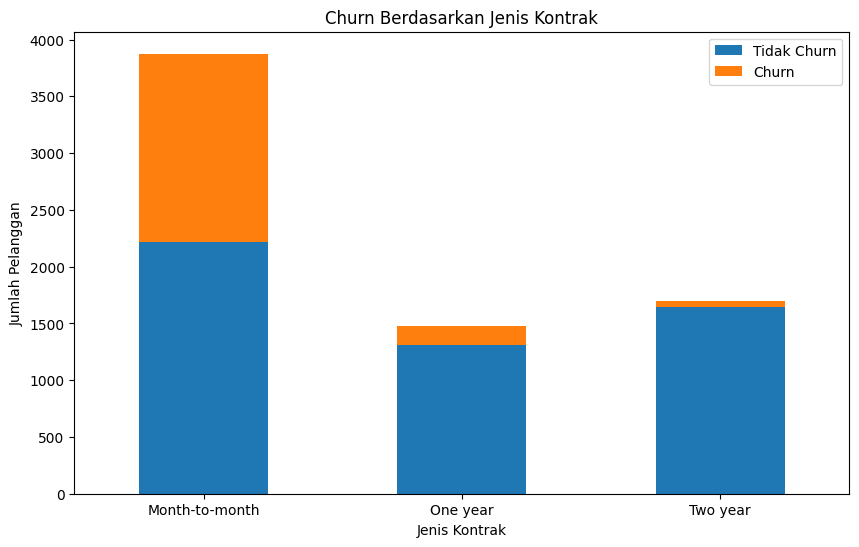

In [21]:
ct = pd.crosstab(df['Contract'], df['Churn'])
ct.plot(kind='bar', stacked=True, figsize=(10, 6))


plt.xticks(rotation=0)
plt.xlabel('Jenis Kontrak')
plt.ylabel('Jumlah Pelanggan')
plt.title('Churn Berdasarkan Jenis Kontrak')
plt.legend(['Tidak Churn', 'Churn'])
plt.show()

**Interpretasi:**

Grafik ini menunjukkan tingkat churn (pelanggan yang berhenti/pindah) berdasarkan jenis kontrak:

  - Kontrak Bulanan (Month-to-month): Memiliki jumlah pelanggan terbanyak sekaligus tingkat churn paling tinggi (proporsi warna oranye sangat besar).   
  - Kontrak 1 Tahun (One year): Tingkat churn jauh lebih rendah dibandingkan kontrak bulanan.   
  - Kontrak 2 Tahun (Two year): Memiliki tingkat churn paling rendah (hampir seluruhnya tetap berlangganan).   

Kesimpulan:
  - Semakin panjang durasi kontrak pelanggan, semakin kecil kemungkinan mereka untuk churn (pindah/berhenti). Pelanggan dengan kontrak bulanan adalah kelompok yang paling rentan pergi.

### b) Lama Berlangganan (Tenure) vs Churn

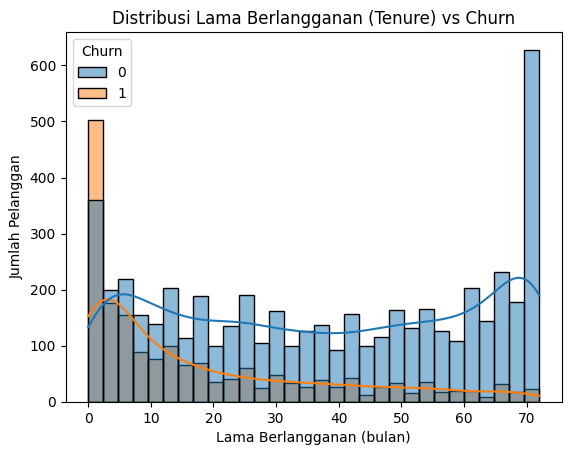

In [23]:
sns.histplot(data=df, x='tenure', hue='Churn',bins=30, kde=True)
plt.title('Distribusi Lama Berlangganan (Tenure) vs Churn')
plt.xlabel('Lama Berlangganan (bulan)')
plt.ylabel('Jumlah Pelanggan')
plt.show()

**Interpretasi:**

Grafik ini menunjukkan hubungan antara lama berlangganan (tenure) dengan risiko churn (berhenti berlangganan):   

- Pelanggan Baru (0–10 Bulan): Risiko churn paling tinggi (bagian oranye/1 paling tinggi di bulan-bulan awal). Banyak pelanggan yang berhenti dalam waktu singkat.   
- Pelanggan Lama (di atas 60–70 Bulan): Sangat setia dan hampir tidak ada yang churn (didominasi warna biru/0).   

Kesimpulan:
  - Semakin lama seseorang berlangganan, semakin loyal mereka dan semakin kecil kemungkinannya untuk berhenti. Pelanggan baru adalah kelompok yang paling rentan pergi.

### c) Tagihan Bulanan vs Churn

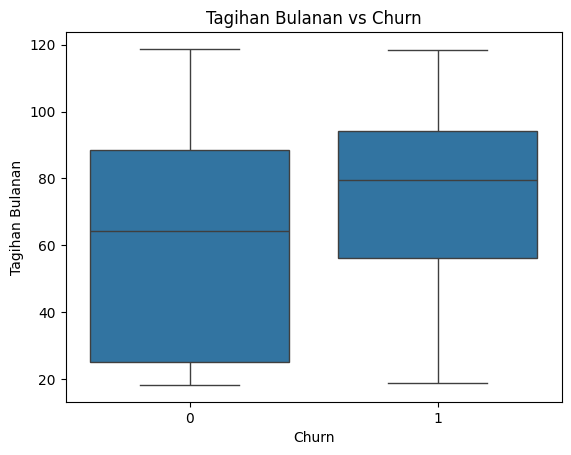

In [27]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Tagihan Bulanan vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tagihan Bulanan')
plt.show()

**Interpretasi:**

Grafik ini menunjukkan hubungan antara besarnya tagihan bulanan dengan keputusan pelanggan untuk churn (berhenti berlangganan):   

  - Tidak Churn (0): Memiliki rata-rata (median) tagihan yang lebih rendah, yaitu sekitar 65.   
  - Churn (1): Memiliki rata-rata (median) tagihan yang lebih tinggi, yaitu sekitar 80, dengan sebagian besar berada di rentang tagihan tinggi (sekitar 55–95).   

Kesimpulan:
  - Pelanggan dengan tagihan bulanan yang lebih mahal cenderung lebih mudah churn (berhenti berlangganan)

## Preprocessing with ColumnTransformer

Kita pisahkan kolom numerik & kategorikal, lalu susun `ColumnTransformer`:

- Kolom **numerik** → `StandardScaler` (samakan skala).
- Kolom **kategorikal** → `OneHotEncoder` (ubah teks jadi kolom 0/1).

Membungkusnya dalam `Pipeline` memastikan scaling/encoding hanya "belajar" dari data latih,
sehingga **tidak ada kebocoran data** (data leakage) ke data uji.

In [28]:
#Pisahkan X dan y
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [30]:
#Pisahkan X categorical dengan X num
num_col = X.select_dtypes(include=np.number).columns.to_list()
cat_col = X.select_dtypes(exclude=np.number).columns.to_list()
#pantau hasil
print(f'Jumlah kolom numerik: {(num_col)}')
print(f'Jumlah kolom kategorikal: {len(cat_col)} kolom')
#

Jumlah kolom numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah kolom kategorikal: 15 kolom


In [31]:
#Gunakan Pipeline ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_col),
    ('cat', OneHotEncoder(handle_unknown="ignore"), cat_col)
])

In [32]:
#Pisahkan Data latih dengan Data testing 80:20
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

## Modeling:

Kita gabungkan preprocessor & model `LogisticRegression` dalam satu `Pipeline`, lalu cari hyperparameter terbaik dengan `GridSearchCV` kecil (mencoba beberapa nilai `C` = kekuatan regularisasi).

Skoring memakai **ROC-AUC** karena data tidak seimbang.

### Pipeline + GridSearch

In [35]:
pipe = Pipeline([
    ('prep', preprocessor),
    ('algo', LogisticRegression(max_iter=1000,
                                class_weight="balanced",
                                solver="liblinear",
                                random_state=42))
])

param_grid = {
    'algo__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(pipe, param_grid=param_grid, scoring="roc_auc", cv=5, n_jobs=1)
grid.fit(X_train, y_train)

print(f"Best parameter: {grid.best_params_}")
print(f"Best score: {grid.best_score_:.3f}")

Best parameter: {'algo__C': 100}
Best score: 0.846


**Interpretasi:**


Best parameter: {'algo__C': 100}:
  - Dari semua pilihan nilai C yang diuji (0.001 hingga 100), nilai C = 100 adalah setelan terbaik yang memberikan performa paling optimal untuk model Logistic Regression.

Best score: 0.846:
  - Skor performa terbaik (berdasarkan metrik ROC-AUC) yang berhasil dicapai adalah 0.846 (atau 84.6%). Ini menunjukkan model memiliki kemampuan yang sangat baik dalam membedakan pelanggan yang akan churn dan yang tidak.

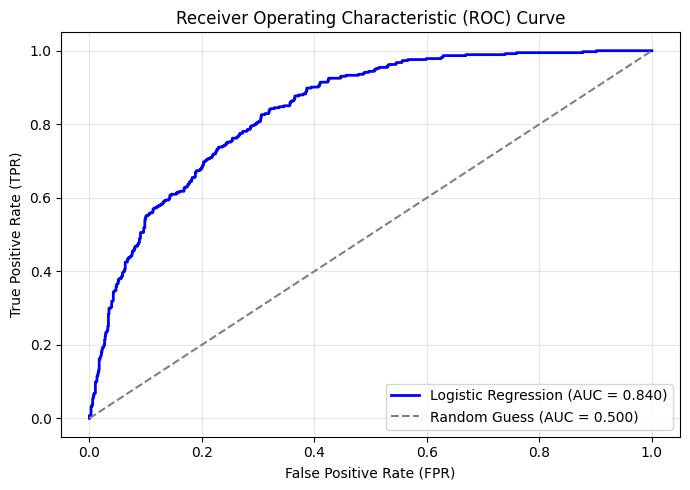

In [36]:
# 1. Ambil probabilitas prediksi untuk kelas positif (Churn = 1)
y_pred_proba = grid.best_estimator_.predict_proba(X_test)[:, 1]

# 2. Hitung nilai FPR, TPR, dan Thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# 3. Hitung skor AUC pada data test
auc_score = roc_auc_score(y_test, y_pred_proba)

# 4. Plot Kurva ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'Logistic Regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.500)')

# Formatting grafik
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretasi:**

Berikut interpretasi sederhana dari kurva ROC di atas:
  - Skor AUC (0.840): Model memiliki performa sebesar 84%, yang tergolong sangat baik (good classification) dalam membedakan pelanggan yang akan churn dan yang tidak.   
  - Bentuk Kurva (Garis Biru): Melengkung jauh di atas garis putus-putus acak (Random Guess). Semakin garis biru mendekati pojok kiri atas, semakin akurat model dalam membuat prediksi.   
  - Garis Abu-abu Putus-putus (AUC = 0.500): Merupakan garis acak (tebakan 50:50/lempar koin) sebagai pembanding dasar.   

Kesimpulan:
  - Model Logistic Regression ini terbukti efektif dan handal untuk memprediksi risiko churn pelanggan.

## Evaluation on Data Test

In [37]:
best = grid.best_estimator_
y_pred = best.predict(X_test)
y_pred_proba = best.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")
print(classification_report(y_test, y_pred,
                            target_names=["Bertahan", "Churn"]))

Accuracy: 73.81%
ROC-AUC: 0.840
              precision    recall  f1-score   support

    Bertahan       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Berikut interpretasi sederhana dari laporan evaluasi model di atas:

  - Accuracy (73.81% / 0.74):

    - Secara keseluruhan, model menebak dengan benar 74% dari total seluruh pelanggan (baik yang bertahan maupun yang churn).

  - ROC-AUC (0.840):

    - Performa pemisah model tergolong sangat baik (84%) dalam membedakan mana pelanggan yang berisiko churn dan mana yang bertahan.

Performa Per Kelas (Bertahan vs Churn)

  - Pelanggan Bertahan (Kelas Major/0):

    - Precision (0.90): Dari semua pelanggan yang ditebak akan bertahan, 90% benar-benar bertahan.
    - Recall (0.72): Model berhasil mendeteksi 72% dari total keseluruhan pelanggan yang sebenarnya bertahan.

  - Pelanggan Churn (Kelas Fokus/1):
    - Recall (0.78): Paling krusial untuk bisnis. Model berhasil mendeteksi 78% dari seluruh pelanggan yang berpotensi churn (hanya 22% pelanggan churn yang lolos dari deteksi).
    - Precision (0.50): Saat model menebak seseorang akan churn, kemungkinannya tepat adalah 50% (setengahnya ternyata masih bertahan/alarm palsu).
    - F1-Score (0.61): Keseimbangan antara Precision dan Recall untuk kelas churn.


Kesimpulan Bisnis

Model ini dirancang dengan kecenderungan sensitif terhadap pelanggan yang mau churn (karena efek penggunaan class_weight="balanced"):

  - Keuntungan: Sangat bagus untuk mencegah timbulnya churn karena berhasil menangkap 78% pelanggan yang akan pergi.

  - Konsekuensi: Akan ada beberapa false alarm (50% pelanggan yang ditebak churn ternyata sebenarnya bertahan), sehingga strategi retensi/promo yang diberikan sebaiknya berbiaya rendah agar hemat anggaran

## Confussion Matrix & ROC Curve

Text(0.5, 1.0, 'ROC Curve')

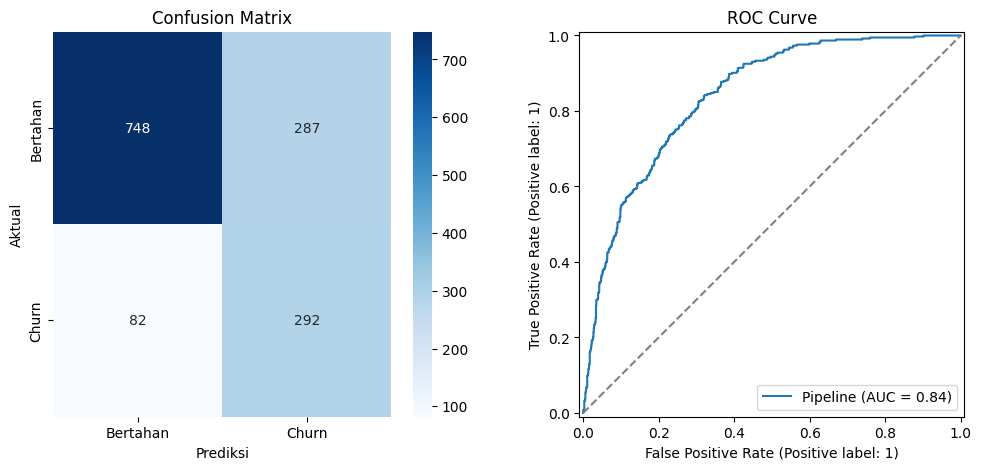

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt="d",
            xticklabels=["Bertahan", "Churn"],
            yticklabels=["Bertahan", "Churn"],
            cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")


# Plot ROC Curve
RocCurveDisplay.from_estimator(best, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC Curve")

**Interpretasi:**

Confusion Matrix (Grafik Kiri)
- 748 (Tebakan Benar - Bertahan): Pelanggan yang aslinya bertahan dan ditebak Bertahan.   
- 292 (Tebakan Benar - Churn): Pelanggan yang aslinya churn dan berhasil ditebak Churn.   
- 82 (Salah Tebak / Miss): Pelanggan yang aslinya churn, tapi salah ditebak Bertahan (lolos dari deteksi).   
- 287 (Alarm Palsu): Pelanggan yang aslinya bertahan, tapi salah ditebak Churn.   

ROC Curve (Grafik Kanan)
  - Skor AUC = 0.84: Nilai ini menunjukkan bahwa kemampuan pemisah model dalam membedakan pelanggan yang churn dan bertahan tergolong sangat baik (84%).   
  - Bentuk Kurva: Garis biru melengkung tinggi menjauhi garis acak diagonal (putus-putus), menandakan prediksi model jauh lebih akurat daripada sekadar tebakan acak.   

Kesimpulan:
  - Model sangat efektif karena berhasil menangkap mayoritas pelanggan yang ingin pergi (292 dari 374 total pelanggan churn), meskipun memiliki konsekuensi timbulnya beberapa alarm palsu (287).   

## Apa yang Mendorong Churn ?

In [49]:
# Ambil nama fitur setelah one-hot encoding
feat_name = best.named_steps["prep"].get_feature_names_out()
coefs = best.named_steps["algo"].coef_[0]

importance_feat = pd.DataFrame({
    "fitur": feat_name,
    "coef": coefs
})

importance_feat.sort_values(by="coef", ascending=False, inplace=True)
importance_feat.head(10)

,fitur,coef
16,cat__InternetService_Fiber optic,1.566738
35,cat__StreamingMovies_Yes,0.687729
32,cat__StreamingTV_Yes,0.675184
36,cat__Contract_Month-to-month,0.616817
3,num__TotalCharges,0.527608
14,cat__MultipleLines_Yes,0.431746
26,cat__DeviceProtection_Yes,0.337886
23,cat__OnlineBackup_Yes,0.280770
11,cat__PhoneService_Yes,0.219074
43,cat__PaymentMethod_Electronic check,0.203252


/tmp/ipykernel_1954/1098964094.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_feat, x="coef", y="fitur",


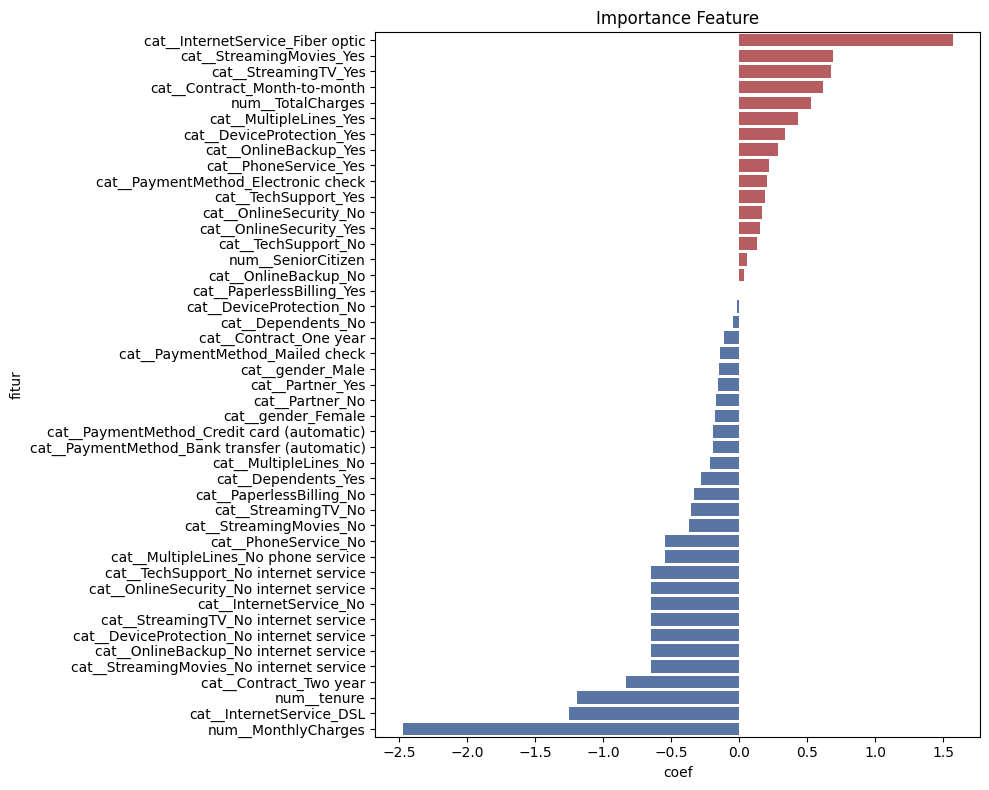

In [50]:
#Visualisasikan Importance Feature
plt.figure(figsize=(10,8))
sns.barplot(data=importance_feat, x="coef", y="fitur",
            palette=["#C44E52" if v > 0 else "#4C72B0" for v in importance_feat["coef"]])
plt.title("Importance Feature")
plt.tight_layout()
plt.show()

**Interpretasi:**

Berikut interpretasi sederhana dari faktor-faktor utama pada grafik tersebut:

Fitur Utama yang Mempertahankan Pelanggan (Nilai Negatif / Biru)Fitur-fitur ini mencegah terjadinya churn (membuat pelanggan tetap bertahan):   
  - num__MonthlyCharges & cat__InternetService_DSL: Tagihan bulanan yang terkontrol/kompetitif serta penggunaan layanan DSL menjadi pendorong paling kuat yang membuat pelanggan enggan untuk pindah.   
  - num__tenure: Semakin lama durasi pelanggan telah berlangganan (tenure), semakin setia mereka untuk tetap bertahan.   
  - cat__Contract_Two year: Pelanggan yang mengambil kontrak jangka panjang 2 tahun jauh lebih stabil dan kecil kemungkinannya untuk berhenti.   


Fitur Utama yang Mendorong Churn (Nilai Positif / Merah)Fitur-fitur ini meningkatkan risiko churn (membuat pelanggan cenderung berhenti/pindah):    
  - cat__InternetService_Fiber optic: Layanan Fiber optic menjadi faktor risiko utama pelanggan pindah (kemungkinan karena harga yang lebih tinggi atau keluhan teknis).   
  - cat__StreamingMovies_Yes & cat__StreamingTV_Yes: Pelanggan yang menambahkan paket hiburan streaming lebih mudah churn.   
  - cat__Contract_Month-to-month: Jenis kontrak bulanan sangat rentan membuat pelanggan pergi kapan saja.   num__TotalCharges: Total akumulasi pengeluaran yang tinggi juga berpotensi memicu pelanggan mencari alternatif lain.

## **Kesimpulan & Rekomendasi Bisnis Berdasarkan Hasil Analisis & Model**

Berdasarkan eksplorasi data (EDA) dan interpretasi koefisien dari model **Logistic Regression** yang telah kita bangun, berikut adalah poin-faktor kunci pendorong retensi dan churn pelanggan, serta rekomendasi strategis untuk divisi bisnis:

---

#### **1. Dorong Migrasi dari Kontrak Bulanan ke Jangka Panjang**
*   **Insight**: Kontrak bulanan (*Month-to-month*) merupakan salah satu faktor pendorong utama terjadinya churn tertinggi. Sebaliknya, pelanggan dengan kontrak 2 tahun memiliki tingkat loyalitas yang sangat tinggi dan paling stabil.
*   **Rekomendasi Tindakan**:
    *   Berikan insentif berupa potongan harga (*discount*) atau nilai tambah (seperti kuota ekstra) jika pelanggan bersedia beralih dari kontrak bulanan ke kontrak minimal 1 atau 2 tahun.
    *   Terapkan biaya penalti pembatalan kontrak yang transparan namun tetap kompetitif agar menekan keinginan berpindah secara mendadak.

#### **2. Evaluasi Layanan Fiber Optic**
*   **Insight**: Layanan *Fiber optic* memiliki koefisien positif terbesar terhadap churn. Ini mengindikasikan pelanggan merasa biaya yang dikeluarkan tidak sebanding dengan kualitas yang didapatkan, atau terdapat masalah teknis/gangguan jaringan yang sering dikeluhkan.
*   **Rekomendasi Tindakan**:
    *   Lakukan survei kepuasan pelanggan (*CSAT*) khusus pengguna *Fiber optic* untuk mengidentifikasi akar masalah (apakah karena harga yang dirasa terlalu mahal atau masalah kestabilan jaringan).
    *   Sediakan paket promo *bundling* atau penyesuaian harga khusus agar pelanggan tidak merasa terbebani dengan tarif bulanan (*Monthly Charges*) yang tinggi.

#### **3. Fokus Retensi Terarah pada Pelanggan Baru (Tenure Rendah)**
*   **Insight**: Pelanggan baru pada rentang **0 hingga 10 bulan pertama** memiliki risiko churn paling tinggi. Setelah melewati fase kritis ini, loyalitas pelanggan meningkat secara signifikan.
*   **Rekomendasi Tindakan**:
    *   Rancang program *Onboarding* yang ramah bagi pelanggan baru, seperti layanan bantuan prioritas (*customer care*) gratis di 3 bulan pertama.
    *   Kirimkan program loyalitas berkala pada bulan ke-3, ke-6, dan ke-9 untuk menjaga keterikatan (*engagement*) mereka.

#### **4. Optimasi Biaya Kampanye Retensi menggunakan Model**
*   **Insight**: Model kita memiliki **Recall sebesar 78%** untuk kelas Churn, yang berarti model mampu mengidentifikasi sebagian besar pelanggan yang akan pergi. Namun, **Precision** berada di angka **50%**, yang memicu adanya *false alarm* (menebak pelanggan akan churn padahal sebenarnya bertahan).
*   **Rekomendasi Tindakan**:
    *   Gunakan taktik retensi yang **berbiaya rendah** (low cost) namun bernilai tinggi (high value) untuk pelanggan yang diprediksi churn oleh model. Contohnya: pemberian konten edukasi, penawaran peningkatan fitur gratis secara terbatas, atau prioritas layanan.
    *   Hindari langsung memberikan diskon tunai yang besar untuk meminimalisir pemborosan anggaran pemasaran pada kelompok *false alarm* tersebut.